In [1]:
import sys

print(sys.executable)

c:\Users\Lenovo\Downloads\Desktop\UAE_Weather_Analytics\.venv\Scripts\python.exe


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Database connection
from sqlalchemy import create_engine, text

# System utilities
import sys
import warnings

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("All libraries imported successfully!")
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Python version: 3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]
Pandas version: 3.1.1
NumPy version: 2.5.5


In [3]:
# Import existing database connection function

import sys
from pathlib import Path

# Add src directory to Python path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

# Import existing ETL database connection function
from load import get_database_engine

# Create database engine
engine = get_database_engine()

print("MySQL engine created successfully!")

MySQL engine created successfully!


In [4]:
from sqlalchemy import text

try:
    with engine.connect() as connection:
        result = connection.execute(
            text("SELECT DATABASE(), VERSION()")
        )

        database, version = result.fetchone()

        print("Database connection successful!")
        print("Database:", database)
        print("MySQL Version:", version)

except Exception as e:
    print("Database connection failed:", e)

Database connection successful!
Database: uae_weather_analytics
MySQL Version: 8.0.46


In [5]:
query = text("""
    SELECT *
    FROM hourly_forecasts
""")

with engine.connect() as connection:
    df_forecasts = pd.read_sql(query, connection)

print("Data loaded successfully!")
print("Rows:", df_forecasts.shape[0])
print("Columns:", df_forecasts.shape[1])

Data loaded successfully!
Rows: 1728
Columns: 12


In [6]:
df_forecasts.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              1728 non-null   int64         
 1   city            1728 non-null   str           
 2   latitude        1728 non-null   float64       
 3   longitude       1728 non-null   float64       
 4   time            1728 non-null   datetime64[us]
 5   collected_at    1728 non-null   datetime64[us]
 6   temperature     1728 non-null   float64       
 7   humidity        1728 non-null   int64         
 8   feels_like      1728 non-null   float64       
 9   precipitation   1728 non-null   float64       
 10  wind_speed      1728 non-null   float64       
 11  wind_direction  1728 non-null   int64         
dtypes: datetime64[us](2), float64(6), int64(3), str(1)
memory usage: 162.1 KB


In [7]:
df_forecasts.describe()

,id,latitude,longitude,time,collected_at,temperature,humidity,feels_like,precipitation,wind_speed,wind_direction
count,1728.00,1728.00,1728.00,1728,1728,1728.00,1728.00,1728.00,1728.00,1728.00,1728.00
mean,864.50,25.10,55.14,2026-11-22 01:43:20,2026-11-21 13:52:44.333333,26.36,63.57,28.50,0.00,8.16,214.85
min,1.00,24.43,54.36,2026-11-20 20:00:00,2026-11-20 19:50:05,22.30,35.00,23.60,0.00,0.40,3.00
25%,432.75,25.02,55.04,2026-11-21 17:00:00,2026-11-21 10:52:03,24.70,57.00,27.30,0.00,4.97,148.00
50%,864.50,25.27,55.33,2026-11-22 02:00:00,2026-11-21 15:16:50,26.40,64.00,28.60,0.00,7.55,242.00
75%,1296.25,25.34,55.43,2026-11-22 11:00:00,2026-11-21 18:46:51,27.90,71.00,29.60,0.00,10.80,276.00
max,1728.00,25.42,55.53,2026-11-23 10:00:00,2026-11-22 10:46:47,32.10,85.00,34.10,0.00,18.80,360.00
std,498.97,0.39,0.46,NaN,NaN,2.13,9.92,1.95,0.00,3.98,80.26


In [8]:
missing_values = pd.DataFrame({
    "Missing_Count": df_forecasts.isnull().sum(),
    "Missing_Percentage": (
        df_forecasts.isnull().sum() / len(df_forecasts) * 100
    )
})

missing_values

,Missing_Count,Missing_Percentage
id,0,0.00
city,0,0.00
latitude,0,0.00
longitude,0,0.00
time,0,0.00
collected_at,0,0.00
temperature,0,0.00
humidity,0,0.00
feels_like,0,0.00
precipitation,0,0.00


In [9]:
print("Exact duplicate rows:",
      df_forecasts.duplicated().sum())

print("Duplicate primary IDs:",
      df_forecasts["id"].duplicated().sum())

print("Duplicate forecast records:",
      df_forecasts.duplicated(
          subset=["city", "time", "collected_at"]
      ).sum())

Exact duplicate rows: 0
Duplicate primary IDs: 0
Duplicate forecast records: 0


In [10]:
city_counts = (
    df_forecasts["city"]
    .value_counts()
    .rename_axis("City")
    .reset_index(name="Record_Count")
)

city_counts

,City,Record_Count
0,Abu Dhabi,432
1,Ajman,432
2,Dubai,432
3,Sharjah,432


In [11]:
print("Forecast start:", df_forecasts["time"].min())
print("Forecast end:", df_forecasts["time"].max())

print("\nCollection start:", df_forecasts["collected_at"].min())
print("Collection end:", df_forecasts["collected_at"].max())

Forecast start: 2026-11-20 20:00:00
Forecast end: 2026-11-23 10:00:00

Collection start: 2026-11-20 19:50:05
Collection end: 2026-11-22 10:46:47


In [12]:
weather_columns = [
    "temperature",
    "humidity",
    "feels_like",
    "precipitation",
    "wind_speed",
    "wind_direction"
]

df_forecasts[weather_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature,1728.00,26.36,2.13,22.30,24.70,26.40,27.90,32.10
humidity,1728.00,63.57,9.92,35.00,57.00,64.00,71.00,85.00
feels_like,1728.00,28.50,1.95,23.60,27.30,28.60,29.60,34.10
precipitation,1728.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
wind_speed,1728.00,8.16,3.98,0.40,4.97,7.55,10.80,18.80
wind_direction,1728.00,214.85,80.26,3.00,148.00,242.00,276.00,360.00


In [13]:
with engine.connect() as connection:
    tables = pd.read_sql(
        text("SHOW TABLES"),
        connection
    )

tables

,Tables_in_uae_weather_analytics
0,hourly_forecasts
1,weather_observations


In [14]:
with engine.connect() as connection:
    observation_schema = pd.read_sql(
        text("DESCRIBE weather_observations"),
        connection
    )

observation_schema

,Field,Type,Null,Key,Default,Extra
0,id,bigint,NO,PRI,None,auto_increment
1,city,varchar(50),NO,MUL,None,
2,latitude,"decimal(10,6)",YES,,None,
3,longitude,"decimal(10,6)",YES,,None,
4,time,datetime,NO,,None,
5,collected_at,datetime,YES,,None,
6,temperature,"decimal(5,2)",YES,,None,
7,humidity,int,YES,,None,
8,feels_like,"decimal(5,2)",YES,,None,
9,precipitation,"decimal(6,2)",YES,,None,


In [15]:
with engine.connect() as connection:
    observation_count = pd.read_sql(
        text("SELECT COUNT(*) AS total_records FROM weather_observations"),
        connection
    )

observation_count

,total_records
0,32


In [16]:
with engine.connect() as connection:
    df_observations = pd.read_sql(
        text("SELECT * FROM weather_observations LIMIT 10"),
        connection
    )

df_observations

,id,city,latitude,longitude,time,collected_at,temperature,humidity,feels_like,precipitation,wind_speed,wind_direction
0,1,Ajman,25.42,55.53,2026-11-19 20:00:00,None,26.30,61,28.50,0.00,5.80,4
1,2,Dubai,25.22,55.26,2026-11-19 20:00:00,None,27.70,46,28.30,0.00,7.40,313
2,3,Abu Dhabi,24.43,54.36,2026-11-19 20:00:00,None,26.80,46,26.70,0.00,10.10,348
3,4,Sharjah,25.32,55.39,2026-11-19 20:00:00,None,26.40,52,27.80,0.00,4.40,325
4,14,Ajman,25.42,55.53,2026-11-19 23:00:00,None,24.60,71,27.00,0.00,6.80,90
5,15,Dubai,25.22,55.26,2026-11-19 23:00:00,None,27.20,48,28.50,0.00,2.90,353
6,16,Abu Dhabi,24.43,54.36,2026-11-19 23:00:00,None,26.20,52,26.40,0.00,11.40,331
7,17,Sharjah,25.32,55.39,2026-11-19 23:00:00,None,25.00,57,26.70,0.00,2.50,82
8,22,Ajman,25.42,55.53,2026-11-19 23:15:00,None,24.50,71,26.90,0.00,6.50,93
9,23,Dubai,25.22,55.26,2026-11-19 23:15:00,None,27.10,48,28.40,0.00,2.50,8


In [17]:
query = text("""
    SELECT *
    FROM weather_observations
    ORDER BY time, city
""")

with engine.connect() as connection:
    df_observations = pd.read_sql(query, connection)

print("Observations loaded successfully!")
print("Rows:", df_observations.shape[0])
print("Columns:", df_observations.shape[1])

Observations loaded successfully!
Rows: 32
Columns: 12


In [18]:
observation_missing = pd.DataFrame({
    "Missing_Count": df_observations.isnull().sum(),
    "Missing_Percentage": (
        df_observations.isnull().sum()
        / len(df_observations) * 100
    )
})

observation_missing

,Missing_Count,Missing_Percentage
id,0,0.00
city,0,0.00
latitude,0,0.00
longitude,0,0.00
time,0,0.00
collected_at,20,62.50
temperature,0,0.00
humidity,0,0.00
feels_like,0,0.00
precipitation,0,0.00


In [19]:
print(
    "Exact duplicate rows:",
    df_observations.duplicated().sum()
)

print(
    "Duplicate IDs:",
    df_observations["id"].duplicated().sum()
)

print(
    "Duplicate city-time records:",
    df_observations.duplicated(
        subset=["city", "time"]
    ).sum()
)

Exact duplicate rows: 0
Duplicate IDs: 0
Duplicate city-time records: 8


In [20]:
df_observations["city"].value_counts()

city
Abu Dhabi    8
Ajman        8
Dubai        8
Sharjah      8
Name: count, dtype: int64

In [21]:
print("First observation:", df_observations["time"].min())
print("Last observation:", df_observations["time"].max())

print(
    "\nUnique observation timestamps:",
    df_observations["time"].nunique()
)

First observation: 2026-11-19 20:00:00
Last observation: 2026-11-20 18:45:00

Unique observation timestamps: 6


In [22]:
observation_weather_columns = [
    "temperature",
    "humidity",
    "feels_like",
    "precipitation",
    "wind_speed",
    "wind_direction"
]

df_observations[
    observation_weather_columns
].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature,32.00,26.47,0.87,24.50,26.18,26.60,26.85,28.00
humidity,32.00,52.28,6.61,41.00,48.00,52.00,53.75,71.00
feels_like,32.00,27.18,0.69,26.40,26.70,27.05,27.57,28.50
precipitation,32.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
wind_speed,32.00,8.86,3.45,2.50,7.25,9.30,11.00,16.20
wind_direction,32.00,257.09,98.83,4.00,281.00,295.00,303.50,353.00


In [24]:
duplicate_observations = (
    df_observations
    .groupby(["city", "time"])
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values(["city", "time"])
)

duplicate_observations

,city,time,record_count
5,Abu Dhabi,2026-11-20 18:45:00,3
11,Ajman,2026-11-20 18:45:00,3
17,Dubai,2026-11-20 18:45:00,3
23,Sharjah,2026-11-20 18:45:00,3


In [25]:
duplicate_details = df_observations.merge(
    duplicate_observations[["city", "time"]],
    on=["city", "time"],
    how="inner"
)

duplicate_details.sort_values(
    ["city", "time", "id"]
)

,id,city,latitude,longitude,time,collected_at,temperature,humidity,feels_like,precipitation,wind_speed,wind_direction
0,44,Abu Dhabi,24.43,54.36,2026-11-20 18:45:00,2026-11-20 18:52:42,26.60,53,27.30,0.00,9.90,297
1,48,Abu Dhabi,24.43,54.36,2026-11-20 18:45:00,2026-11-20 18:54:11,26.60,53,27.30,0.00,9.90,297
2,52,Abu Dhabi,24.43,54.36,2026-11-20 18:45:00,2026-11-20 18:56:23,26.60,53,27.30,0.00,9.90,297
3,42,Ajman,25.42,55.53,2026-11-20 18:45:00,2026-11-20 18:52:42,26.20,48,26.40,0.00,8.50,282
4,46,Ajman,25.42,55.53,2026-11-20 18:45:00,2026-11-20 18:54:11,26.20,48,26.40,0.00,8.50,282
5,50,Ajman,25.42,55.53,2026-11-20 18:45:00,2026-11-20 18:56:23,26.20,48,26.40,0.00,8.50,282
6,43,Dubai,25.22,55.26,2026-11-20 18:45:00,2026-11-20 18:52:42,26.80,56,28.10,0.00,9.30,298
7,47,Dubai,25.22,55.26,2026-11-20 18:45:00,2026-11-20 18:54:11,26.80,56,28.10,0.00,9.30,298
8,51,Dubai,25.22,55.26,2026-11-20 18:45:00,2026-11-20 18:56:23,26.80,56,28.10,0.00,9.30,298
9,45,Sharjah,25.32,55.39,2026-11-20 18:45:00,2026-11-20 18:52:42,25.90,53,26.70,0.00,7.70,281


In [26]:
df_observations.groupby("city").agg(
    Total_Records=("id", "count"),
    Missing_Collection_Time=(
        "collected_at",
        lambda x: x.isna().sum()
    ),
    Available_Collection_Time=(
        "collected_at",
        lambda x: x.notna().sum()
    )
)

,Total_Records,Missing_Collection_Time,Available_Collection_Time
city,,,
Abu Dhabi,8,5,3
Ajman,8,5,3
Dubai,8,5,3
Sharjah,8,5,3


In [27]:
df_observations[
    ["id", "city", "time", "collected_at"]
].sort_values(["time", "city"])

,id,city,time,collected_at
0,3,Abu Dhabi,2026-11-19 20:00:00,NaT
1,1,Ajman,2026-11-19 20:00:00,NaT
2,2,Dubai,2026-11-19 20:00:00,NaT
3,4,Sharjah,2026-11-19 20:00:00,NaT
4,16,Abu Dhabi,2026-11-19 23:00:00,NaT
5,14,Ajman,2026-11-19 23:00:00,NaT
6,15,Dubai,2026-11-19 23:00:00,NaT
7,17,Sharjah,2026-11-19 23:00:00,NaT
8,24,Abu Dhabi,2026-11-19 23:15:00,NaT
9,22,Ajman,2026-11-19 23:15:00,NaT


In [28]:
# Weather columns to compare
weather_columns = [
    'temperature',
    'humidity',
    'feels_like',
    'precipitation',
    'wind_speed',
    'wind_direction'
]

# Find city and weather timestamps that appear more than once
repeated_records = df_observations[
    df_observations.duplicated(
        subset=['city', 'time'],
        keep=False
    )
].copy()

# Sort the records for easier comparison
repeated_records = repeated_records.sort_values(
    ['city', 'time', 'collected_at']
)

# Display repeated records with their weather measurements
repeated_records[
    ['id', 'city', 'time', 'collected_at'] + weather_columns
]

,id,city,time,collected_at,temperature,humidity,feels_like,precipitation,wind_speed,wind_direction
20,44,Abu Dhabi,2026-11-20 18:45:00,2026-11-20 18:52:42,26.60,53,27.30,0.00,9.90,297
21,48,Abu Dhabi,2026-11-20 18:45:00,2026-11-20 18:54:11,26.60,53,27.30,0.00,9.90,297
22,52,Abu Dhabi,2026-11-20 18:45:00,2026-11-20 18:56:23,26.60,53,27.30,0.00,9.90,297
23,42,Ajman,2026-11-20 18:45:00,2026-11-20 18:52:42,26.20,48,26.40,0.00,8.50,282
24,46,Ajman,2026-11-20 18:45:00,2026-11-20 18:54:11,26.20,48,26.40,0.00,8.50,282
25,50,Ajman,2026-11-20 18:45:00,2026-11-20 18:56:23,26.20,48,26.40,0.00,8.50,282
26,43,Dubai,2026-11-20 18:45:00,2026-11-20 18:52:42,26.80,56,28.10,0.00,9.30,298
27,47,Dubai,2026-11-20 18:45:00,2026-11-20 18:54:11,26.80,56,28.10,0.00,9.30,298
28,51,Dubai,2026-11-20 18:45:00,2026-11-20 18:56:23,26.80,56,28.10,0.00,9.30,298
29,45,Sharjah,2026-11-20 18:45:00,2026-11-20 18:52:42,25.90,53,26.70,0.00,7.70,281


In [29]:
# Check whether weather measurements are identical
# for each city and weather timestamp

repeated_check = (
    repeated_records
    .groupby(['city', 'time'])[weather_columns]
    .nunique()
    .reset_index()
)

repeated_check

,city,time,temperature,humidity,feels_like,precipitation,wind_speed,wind_direction
0,Abu Dhabi,2026-11-20 18:45:00,1,1,1,1,1,1
1,Ajman,2026-11-20 18:45:00,1,1,1,1,1,1
2,Dubai,2026-11-20 18:45:00,1,1,1,1,1,1
3,Sharjah,2026-11-20 18:45:00,1,1,1,1,1,1


In [30]:
# Calculate average temperature for each city and forecast hour

temperature_trend = (
    df_forecasts
    .groupby(['city', 'time'])['temperature']
    .mean()
    .reset_index()
)

temperature_trend.head()

,city,time,temperature
0,Abu Dhabi,2026-11-20 20:00:00,26.40
1,Abu Dhabi,2026-11-20 21:00:00,26.30
2,Abu Dhabi,2026-11-20 22:00:00,26.10
3,Abu Dhabi,2026-11-20 23:00:00,26.00
4,Abu Dhabi,2026-11-21 00:00:00,25.70


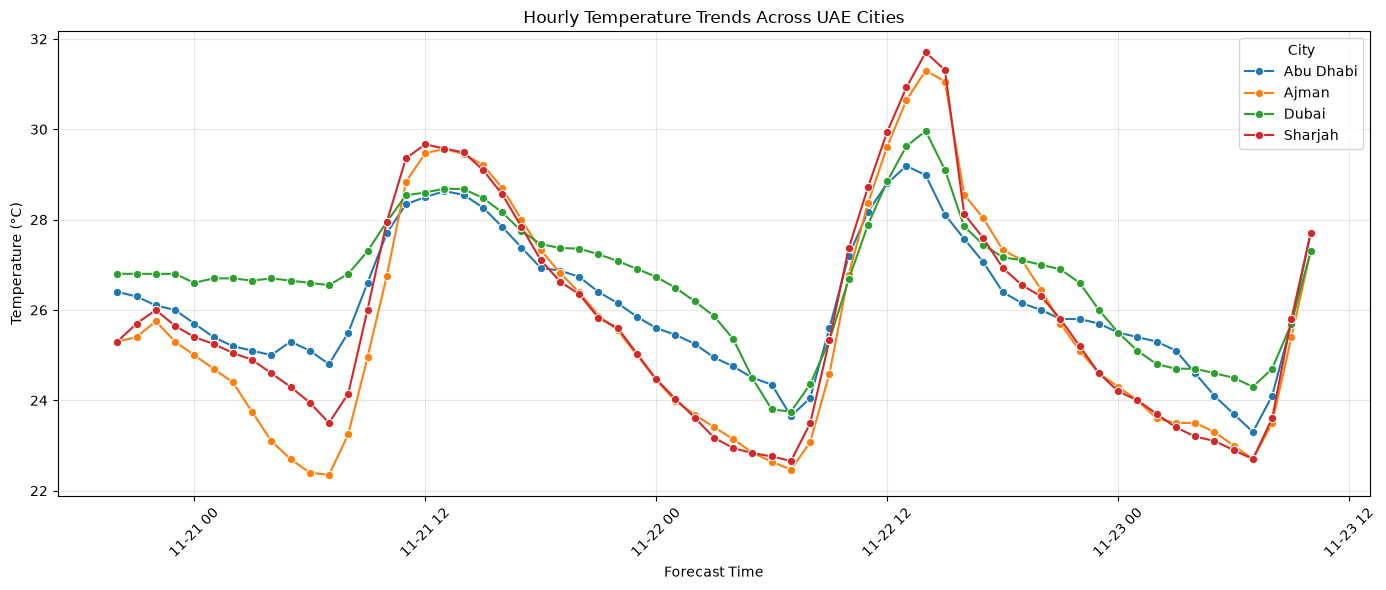

In [31]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=temperature_trend,
    x='time',
    y='temperature',
    hue='city',
    marker='o'
)

plt.title('Hourly Temperature Trends Across UAE Cities')
plt.xlabel('Forecast Time')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.legend(title='City')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


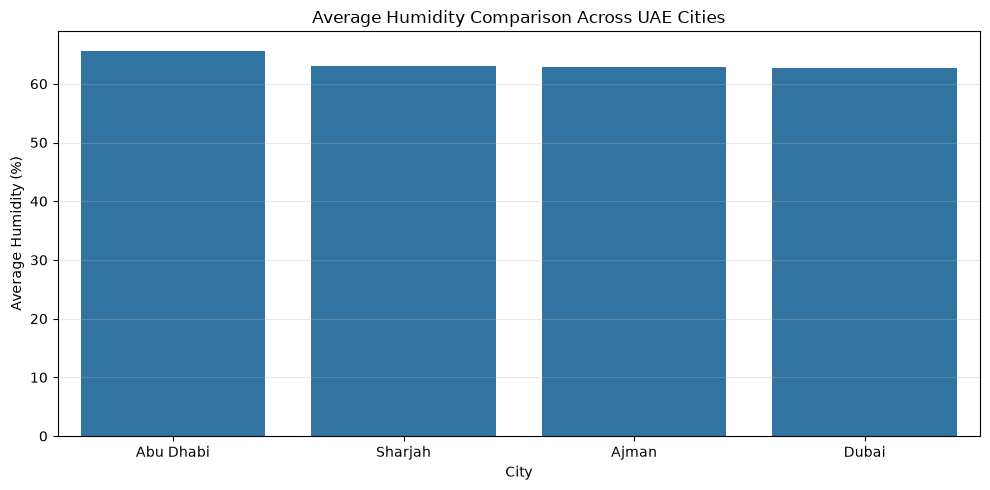

In [32]:
humidity_comparison = (
    df_forecasts
    .groupby('city')['humidity']
    .mean()
    .reset_index()
    .sort_values('humidity', ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=humidity_comparison,
    x='city',
    y='humidity'
)

plt.title('Average Humidity Comparison Across UAE Cities')
plt.xlabel('City')
plt.ylabel('Average Humidity (%)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [33]:
feels_like_comparison = (
    df_forecasts
    .groupby('city')[['temperature', 'feels_like']]
    .mean()
    .reset_index()
)

feels_like_comparison

,city,temperature,feels_like
0,Abu Dhabi,26.36,28.74
1,Ajman,26.01,27.86
2,Dubai,26.87,29.13
3,Sharjah,26.18,28.27


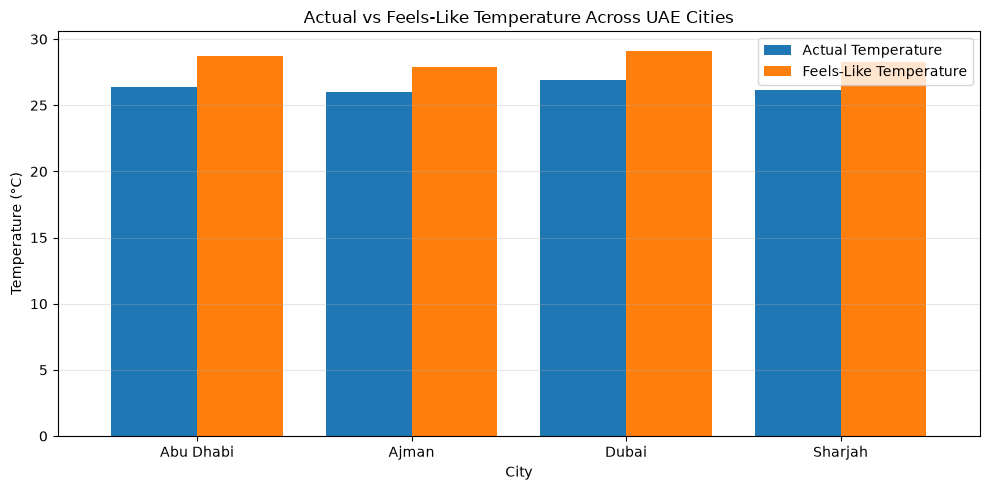

In [34]:
feels_like_comparison.plot(
    x='city',
    y=['temperature', 'feels_like'],
    kind='bar',
    figsize=(10, 5),
    width=0.8
)

plt.title('Actual vs Feels-Like Temperature Across UAE Cities')
plt.xlabel('City')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=0)
plt.legend(['Actual Temperature', 'Feels-Like Temperature'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [35]:
wind_comparison = (
    df_forecasts
    .groupby('city')['wind_speed']
    .mean()
    .reset_index()
    .sort_values('wind_speed', ascending=False)
)

wind_comparison

,city,wind_speed
2,Dubai,8.57
1,Ajman,8.51
0,Abu Dhabi,8.21
3,Sharjah,7.36


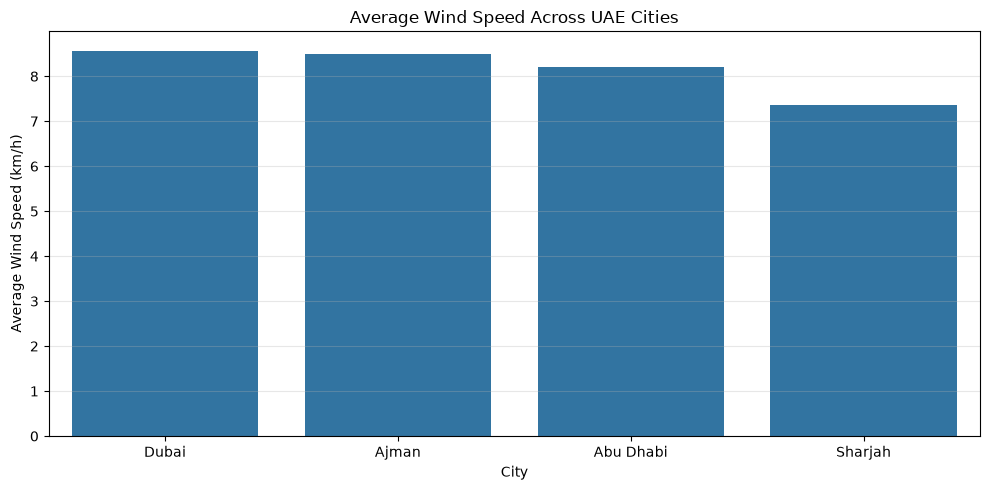

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=wind_comparison,
    x='city',
    y='wind_speed'
)

plt.title('Average Wind Speed Across UAE Cities')
plt.xlabel('City')
plt.ylabel('Average Wind Speed (km/h)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [37]:
# Sort records by city, forecast time and collection time

df_revision = df_forecasts.sort_values(
    ['city', 'time', 'collected_at']
).copy()

# Calculate temperature revision between consecutive collections
df_revision['temperature_revision'] = (
    df_revision
    .groupby(['city', 'time'])['temperature']
    .diff()
)

# Calculate absolute revision
df_revision['absolute_revision'] = (
    df_revision['temperature_revision'].abs()
)

# Display sample results
df_revision[
    [
        'city',
        'time',
        'collected_at',
        'temperature',
        'temperature_revision',
        'absolute_revision'
    ]
].head(20)

,city,time,collected_at,temperature,temperature_revision,absolute_revision
0,Abu Dhabi,2026-11-20 20:00:00,2026-11-20 19:50:05,26.40,NaN,NaN
96,Abu Dhabi,2026-11-20 20:00:00,2026-11-20 19:56:01,26.40,0.00,0.00
1,Abu Dhabi,2026-11-20 21:00:00,2026-11-20 19:50:05,26.30,NaN,NaN
97,Abu Dhabi,2026-11-20 21:00:00,2026-11-20 19:56:01,26.30,0.00,0.00
2,Abu Dhabi,2026-11-20 22:00:00,2026-11-20 19:50:05,26.10,NaN,NaN
98,Abu Dhabi,2026-11-20 22:00:00,2026-11-20 19:56:01,26.10,0.00,0.00
192,Abu Dhabi,2026-11-20 22:00:00,2026-11-20 21:04:11,26.10,0.00,0.00
288,Abu Dhabi,2026-11-20 22:00:00,2026-11-20 21:48:25,26.10,0.00,0.00
3,Abu Dhabi,2026-11-20 23:00:00,2026-11-20 19:50:05,26.00,NaN,NaN
99,Abu Dhabi,2026-11-20 23:00:00,2026-11-20 19:56:01,26.00,0.00,0.00


In [38]:
revision_summary = (
    df_revision
    .groupby('city')['absolute_revision']
    .mean()
    .reset_index()
    .sort_values('absolute_revision', ascending=False)
)

revision_summary

,city,absolute_revision
1,Ajman,0.05
3,Sharjah,0.05
2,Dubai,0.04
0,Abu Dhabi,0.02


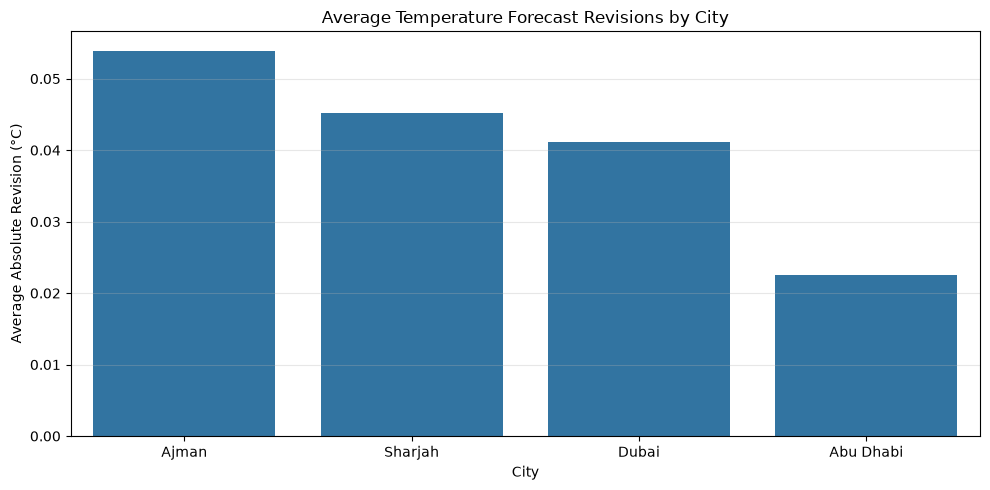

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=revision_summary,
    x='city',
    y='absolute_revision'
)

plt.title('Average Temperature Forecast Revisions by City')
plt.xlabel('City')
plt.ylabel('Average Absolute Revision (°C)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()